In [247]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM


/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [248]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [270]:
############# Upload data ###########
response_matrix_train = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/response_matrix_train.npy' )
response_matrix_train  = response_matrix_train[:50,:]
condition_matrix_train = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/condition_matrix_train.npy' )
condition_matrix_train  = condition_matrix_train[:50,:]

restriction = np.std(response_matrix_train, axis=(0, 1, 2)) > .1
response_matrix_train = response_matrix_train[
    :, :, :, restriction]

N_NEURONS = response_matrix_train.shape[3]

# response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
#                                                          keepdims=True)) / np.std(response_matrix_train,
#                                                                                   axis=(0, 1, 2),
#                                                                                   keepdims=True)
#
# response_matrix_train = torch.tensor(response_matrix_train).float()

In [271]:

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                         keepdims=True)) / np.std(z,
                                                                                  axis=(0, 1),
                                                                                  keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])

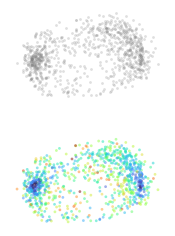

In [583]:
#########################################################################
################ Time series embedding for bwm data  ####################
#########################################################################
x_proj = model.encoder(torch.tensor(response_matrix.T).float()).detach().numpy()

fig = plt.figure(figsize=(2,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])


responses = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
                                             keepdims=True)) / np.std(response_matrix_train,
                                                                      axis=(0, 1, 2),
                                                                      keepdims=True)

data_snr = []
for neuron in range(N_NEURONS):
    means = []
    for t in range(99):
        h = (responses[:, 0, t + 1, neuron] - responses[:, 0, t, neuron]) / (responses[:, 0, t, neuron] + 5)
        means.append(np.abs(np.mean(h)))
    data_snr.append(np.mean(means))

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                         keepdims=True)) / np.std(z,
                                                                                  axis=(0, 1),
                                                                                  keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])


x_proj = TSNE(n_components = 2,perplexity = 400).fit_transform(response_matrix.T)

# # import umap
# fit = umap.UMAP(densmap=True,dens_lambda=5)
# x_proj= fit.fit_transform(response_matrix.T)

sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax0,legend = False,lw = 0,alpha = .25,color='gray')
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax1,legend = False,lw = 0,alpha = .5,hue = data_snr,palette = 'turbo')

for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [150]:
response_matrix_train.shape

(50, 2, 100, 925)

In [ ]:
# Grid search for alpha and beta

In [ ]:
# VAE-Flow

In [ ]:
# VAE with volume preserving flows

In [624]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image
import os

# --- Constants & Hyperparameters ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
LR = 1e-4
EPOCHS = 600
LATENT_DIM = 2
HIDDEN_DIM = 128
INPUT_DIM = 200

# --- Model Components ---

class AdditiveCouplingLayer(nn.Module):
    def __init__(self, dim, hidden_dim):
        super().__init__()
        self.split_idx = dim // 2
        # The translation function 'm'
        self.m = nn.Sequential(
            nn.Linear(self.split_idx, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, dim - self.split_idx)
        )

    def forward(self, z):
        z1, z2 = z[:, :self.split_idx], z[:, self.split_idx:]
        z2 = z2 + self.m(z1) # Additive transformation
        return torch.cat([z1, z2], dim=1)

class VolumePreservingVAE(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim, num_flows=3):
        super().__init__()

        # Encoder: Predicts Mu and LogVar
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2)
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_var = nn.Linear(hidden_dim, latent_dim)

        # Flows: Sequential additive coupling layers
        self.flows = nn.ModuleList([
            AdditiveCouplingLayer(latent_dim, hidden_dim // 2) for _ in range(num_flows)
        ])

        # Decoder: MSE works better with a linear output or Tanh
        # (Removing Sigmoid to allow MSE more freedom)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, input_dim)
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu, logvar = self.fc_mu(h), self.fc_var(h)
        z_0 = self.reparameterize(mu, logvar)

        # log q(z_0)
        log_q_z0 = -0.5 * torch.sum(logvar + (z_0 - mu)**2 / torch.exp(logvar), dim=1)

        # Apply Flows
        z_k = z_0
        for flow in self.flows:
            z_k = flow(z_k)
            z_k = torch.flip(z_k, dims=[1]) # Mix dimensions

        # log q(z_k) = log q(z_0) (because Jacobian determinant is 1)
        return self.decoder(z_k), log_q_z0, z_k

# --- Loss Function ---

def loss_function(x, x_recon, log_q_zk, z_k):
    # MSE Reconstruction: Sum of squared errors
    recon_loss = F.mse_loss(x_recon, x, reduction='sum')

    # Log Prior: log p(z_k) assuming Standard Normal
    log_p_zk = -0.5 * torch.sum(z_k**2 + torch.log(torch.tensor(2 * torch.pi)), dim=1)

    # KLD = E[log q(z_k) - log p(z_k)]
    kld_loss = torch.sum(log_q_zk - log_p_zk)

    return recon_loss + kld_loss

# --- Training Routine ---

#transform = transforms.Compose([transforms.ToTensor()])
labels  = torch.tensor(data_snr).float()
train_loader = DataLoader(TensorDataset(X_data,labels), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(TensorDataset(X_data,labels), batch_size=BATCH_SIZE, shuffle=False)

model = VolumePreservingVAE(INPUT_DIM, HIDDEN_DIM, LATENT_DIM).to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LR)

def train(epoch):
    model.train()
    total_loss = 0
    for batch_idx, data in enumerate(train_loader):

        data = data[0].view(-1, INPUT_DIM).to(DEVICE)
        optimizer.zero_grad()

        recon, log_q_zk, z_k = model(data)
        loss = loss_function(data, recon, log_q_zk, z_k)

        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch} complete. Avg Loss: {total_loss / len(train_loader.dataset):.4f}")

if __name__ == "__main__":
    if not os.path.exists('results'): os.makedirs('results')
    for epoch in range(1, EPOCHS + 1):
        train(epoch)
        # Periodic sampling
        with torch.no_grad():
            sample = torch.randn(64, LATENT_DIM).to(DEVICE)
            sample = model.decoder(sample).cpu()
            #save_image(sample.view(64, 1, 28, 28), f'results/sample_{epoch}.png')

Epoch 1 complete. Avg Loss: 205.1591
Epoch 2 complete. Avg Loss: 203.6619
Epoch 3 complete. Avg Loss: 202.4105
Epoch 4 complete. Avg Loss: 201.0756
Epoch 5 complete. Avg Loss: 199.2603
Epoch 6 complete. Avg Loss: 195.5331
Epoch 7 complete. Avg Loss: 188.7004
Epoch 8 complete. Avg Loss: 176.2786
Epoch 9 complete. Avg Loss: 158.9765
Epoch 10 complete. Avg Loss: 144.0595
Epoch 11 complete. Avg Loss: 133.6542
Epoch 12 complete. Avg Loss: 124.5862
Epoch 13 complete. Avg Loss: 118.5687
Epoch 14 complete. Avg Loss: 114.0225
Epoch 15 complete. Avg Loss: 110.0968
Epoch 16 complete. Avg Loss: 107.0533
Epoch 17 complete. Avg Loss: 103.2301
Epoch 18 complete. Avg Loss: 99.2944
Epoch 19 complete. Avg Loss: 95.1148
Epoch 20 complete. Avg Loss: 91.6410
Epoch 21 complete. Avg Loss: 88.9544
Epoch 22 complete. Avg Loss: 86.4068
Epoch 23 complete. Avg Loss: 84.4470
Epoch 24 complete. Avg Loss: 82.9635
Epoch 25 complete. Avg Loss: 81.6987
Epoch 26 complete. Avg Loss: 80.3277
Epoch 27 complete. Avg Loss: 7

In [625]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

def visualize_latent_distribution(model, device, loader, num_samples=5000):
    model.eval()
    all_z0 = []
    all_zk = []
    all_labels = []

    with torch.no_grad():
        for data, labels in loader:
            data = data.view(-1, INPUT_DIM).to(device)

            # Get the initial sample (before flow)
            h = model.encoder(data)
            mu, logvar = model.fc_mu(h), model.fc_var(h)
            z0 = model.reparameterize(mu, logvar)

            # Get the transformed sample (after flow)
            zk = z0
            for flow in model.flows:
                zk = flow(zk)
                zk = torch.flip(zk, dims=[1])

            all_z0.append(z0.cpu().numpy())
            all_zk.append(zk.cpu().numpy())
            all_labels.append(labels.numpy())

            if len(np.concatenate(all_z0)) >= num_samples:
                break

    # Concatenate and trim
    z0_concat = np.concatenate(all_z0)[:num_samples]
    zk_concat = np.concatenate(all_zk)[:num_samples]
    labels_concat = np.concatenate(all_labels)[:num_samples]

    # Use PCA to project to 2D
    pca_z0 = PCA(n_components=2).fit_transform(z0_concat)
    pca_zk = PCA(n_components=2).fit_transform(zk_concat)

    # Plotting
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))

    # Plot z0 (Standard VAE output)
    scatter2 = ax1.scatter(pca_zk[:, 0], pca_zk[:, 1], color='gray', alpha=0.25, s=4)
    ax1.set_title("Transformed Latent Space ($z_k$) - After Flow")
    ax1.set_xlabel("PC 1")
    ax1.set_ylabel("PC 2")

    # Plot zk (After Volume Preserving Flow)
    scatter2 = ax2.scatter(pca_zk[:, 0], pca_zk[:, 1], c=labels_concat, cmap='turbo', alpha=0.25, s=4)
    ax2.set_title("Transformed Latent Space ($z_k$) - After Flow")
    ax2.set_xlabel("PC 1")
    ax2.set_ylabel("PC 2")

    plt.colorbar(scatter2, ax=ax2, label="Digit Class")
    plt.tight_layout()
    plt.show()

# To use this, call it after training:
# visualize_latent_distribution(model, DEVICE, test_loader)

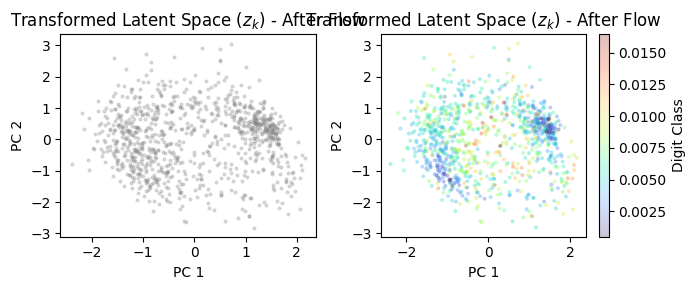

In [626]:
visualize_latent_distribution(model, DEVICE, test_loader)

In [561]:
def analyze_latent_space(model, data_tensor, labels=None):
    """
    Projects the high-dimensional latent space into 2D using PCA
    and saves the plot as a file.
    """
    model.eval()
    with torch.no_grad():
        _, _, z_k = model(data_tensor.to(DEVICE))
        z_k = z_k.cpu().numpy()

    pca = PCA(n_components=2)
    z_2d = pca.fit_transform(z_k)

    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(z_2d[:, 0], z_2d[:, 1], c=labels, cmap='viridis', alpha=0.6)
    if labels is not None:
        plt.colorbar(scatter)
    plt.title("Latent Space Projection (PCA)")
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.savefig('latent_projection.png')
    print("Latent projection saved as 'latent_projection.png'")

Latent projection saved as 'latent_projection.png'


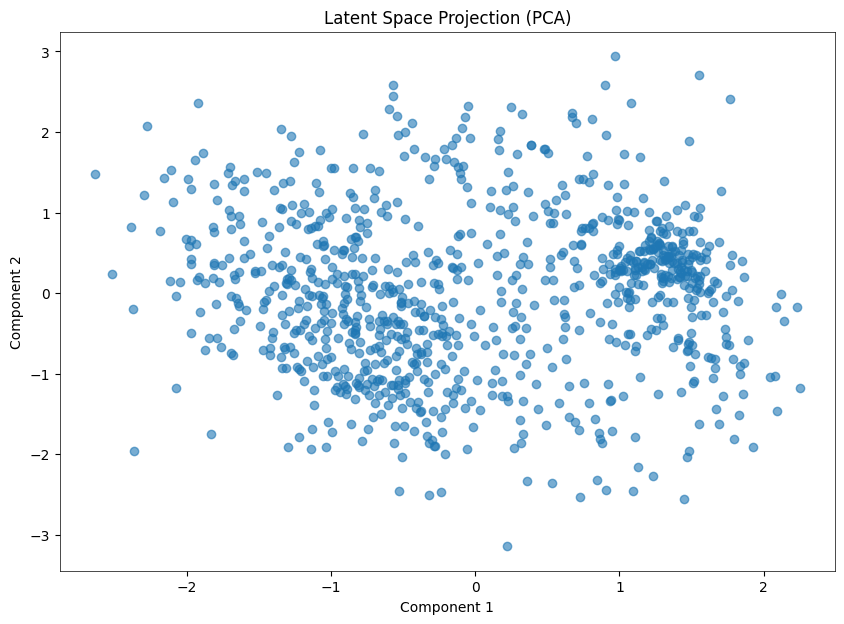

In [569]:
analyze_latent_space(model, X_data, labels=None)

In [552]:
######### VAE with volume preserving flows and jacobian isometry loss #############

In [606]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# 1. Volume-Preserving Householder Flow
class HouseholderFlow(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.v = nn.Parameter(torch.randn(1, dim))

    def forward(self, z):
        v = self.v
        v_norm_sq = torch.sum(v**2) + 1e-8 # Stability epsilon
        dot = torch.matmul(z, v.t())
        z_new = z - 2 * dot * (v / v_norm_sq)
        return z_new

# 2. VAE Model for Continuous Vectors
class VAE_Continuous(nn.Module):
    def __init__(self, input_dim, latent_dim=2, num_flows=2):
        super().__init__()
        self.latent_dim = latent_dim

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, latent_dim * 2)
        )

        # Flows
        self.flows = nn.ModuleList([HouseholderFlow(latent_dim) for _ in range(num_flows)])

        # Decoder (Removed Sigmoid for continuous output)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, input_dim)
        )

    def encode(self, x):
        h = self.encoder(x)
        return h[:, :self.latent_dim], h[:, self.latent_dim:]

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z_0 = self.reparameterize(mu, logvar)

        z_k = z_0
        for flow in self.flows:
            z_k = flow(z_k)

        return self.decoder(z_k), mu, logvar, z_k

# 3. Jacobian Isometry Loss
def compute_iso_loss(z, x_recon):
    batch_size = z.size(0)
    z_dim = z.size(1)
    x_dim = x_recon.size(1)

    # We use vector-Jacobian products to be more efficient
    jacobian = []
    for i in range(x_dim):
        grad_out = torch.zeros_like(x_recon)
        grad_out[:, i] = 1
        # Create_graph=True is critical for backprop through the loss
        grads = torch.autograd.grad(x_recon, z, grad_out, retain_graph=True, create_graph=True)[0]
        jacobian.append(grads.unsqueeze(1))

    J = torch.cat(jacobian, dim=1)
    JTJ = torch.matmul(J.transpose(1, 2), J)
    I = torch.eye(z_dim).to(z.device).unsqueeze(0).repeat(batch_size, 1, 1)
    return F.mse_loss(JTJ, I)

# 4. Training Loop
def train_continuous_vae():
    # Configuration
    input_dim = 200  # Size of your continuous vectors
    latent_dim = 2
    batch_size = 64
    epochs = 100
    iso_lambda = 1

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Dummy data: Replace this with your actual continuous vector dataset

    dataset = TensorDataset(X_data, torch.tensor(data_snr).float())
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    model = VAE_Continuous(input_dim=input_dim, latent_dim=latent_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for batch in loader:
            data = batch[0].to(device)
            optimizer.zero_grad()

            recon, mu, logvar, z_k = model(data)

            # 1. Reconstruction Loss: MSE
            recon_loss = F.mse_loss(recon, data, reduction='sum')

            # 2. KL Divergence
            kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

            # 3. Isometry Loss
            iso_loss = compute_iso_loss(z_k, recon)

            loss = recon_loss + kl_loss + (iso_lambda * iso_loss)

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1} | Loss: {total_loss / len(loader.dataset):.4f}")

    return model

if __name__ == "__main__":
    model = train_continuous_vae()

Epoch 10 | Loss: 80.6499
Epoch 20 | Loss: 71.0897
Epoch 30 | Loss: 69.5679
Epoch 40 | Loss: 68.7355
Epoch 50 | Loss: 67.9065
Epoch 60 | Loss: 67.1967
Epoch 70 | Loss: 66.2065
Epoch 80 | Loss: 64.7154
Epoch 90 | Loss: 62.8562
Epoch 100 | Loss: 61.2765


4
4
4
4
4
4
4
4
4
4
4
4
4
4
4


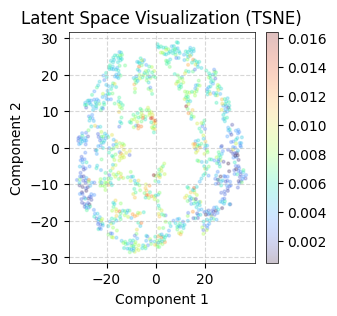

In [607]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import numpy as np

def visualize_latent_space(model, dataloader, device, method='pca'):
    """
    Projects and plots the latent space z_k (after flows).
    """
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for batch in dataloader:
            # Handle both (data, label) and (data,) loaders
            data = batch[0].to(device) if isinstance(batch, list) else batch.to(device)

            # We want the latent representation after the flow (z_k)
            print(len(model(data)))
            _, _, _, z_k = model(data)

            latents.append(z_k.cpu().numpy())

            # If you have labels/categories, append them for coloring
            if isinstance(batch, list) and len(batch) > 1:
                labels.append(batch[1].numpy())

    latents = np.concatenate(latents, axis=0)

    # Project to 2D
    if method.lower() == 'pca':
        reducer = PCA(n_components=2)
    else:
        reducer = TSNE(n_components=2, perplexity=30)

    z_embedded = reducer.fit_transform(latents)

    # Plotting
    plt.figure(figsize=(3, 3))
    if labels:
        labels = np.concatenate(labels, axis=0)
        scatter = plt.scatter(z_embedded[:, 0], z_embedded[:, 1], c=labels, cmap='turbo', alpha=0.25, s=4)
        plt.colorbar(scatter)
    else:
        plt.scatter(z_embedded[:, 0], z_embedded[:, 1], alpha=0.6, s=10, color='blue')

    plt.title(f'Latent Space Visualization ({method.upper()})')
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

# Example Usage (after training):
dataset = TensorDataset(X_data, torch.tensor(data_snr).float())

loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
visualize_latent_space(model, loader, 'cpu', method='tsne')

In [566]:
model(data)

(tensor([[ 1.2970,  1.2738,  1.2290,  ...,  0.1656,  0.0538,  0.1168],
         [-0.9434, -0.9220, -0.9111,  ...,  1.4112,  1.4088,  1.4243],
         [-0.0046, -0.0043, -0.0467,  ..., -0.5319, -0.5149, -0.5185],
         ...,
         [-0.2285, -0.1899, -0.1925,  ..., -0.6509, -0.6556, -0.6476],
         [-0.8023, -0.7642, -0.7831,  ...,  0.7494,  0.7683,  0.7462],
         [-1.7015, -1.7301, -1.6776,  ...,  0.9012,  0.8782,  0.9422]],
        grad_fn=<AddmmBackward0>),
 tensor([3.9627, 4.5307, 4.4771, 4.7072, 4.7938, 3.9029, 2.7310, 4.5187, 3.1207,
         5.4247, 3.4885, 4.3472, 5.7250, 3.9854, 2.4923, 4.7137, 5.2084, 4.8238,
         4.9780, 5.0988, 4.2271, 5.4520, 5.0181, 3.7093, 3.2295, 5.3549, 3.3895,
         2.7437, 4.0584], grad_fn=<MulBackward0>),
 tensor([[ 0.4140,  2.6750],
         [ 0.2450, -1.5531],
         [-1.2470, -0.6908],
         [ 1.0430,  0.6895],
         [-0.4021, -1.7976],
         [ 1.1798,  0.9598],
         [ 0.7954,  1.0001],
         [ 0.0723, -1.2497]